# 9. KKT conditions and solution methods

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, nnls, curve_fit
import ipywidgets as widgets
from IPython.display import display, clear_output

rng = np.random.default_rng(2026)
np.set_printoptions(precision=5, suppress=True)


## 9.1 KKT in one dimension [CO 14.6]

### Task
For a differentiable objective $f_0$ and inequality $f_1\le0$, the four KKT conditions are primal feasibility $f_1(x^*)\le0$, dual feasibility $\lambda^*\ge0$, stationarity $f_0'(x^*)+\lambda^*f_1'(x^*)=0$, and complementary slackness $\lambda^*f_1(x^*)=0$. Apply them to $\min -x$ subject to $e^x-1\le0$ and to the problem of Exercise 7.1; solve by hand and check each condition numerically. Plot $\nabla f_0(x)+\lambda^*\nabla f_1(x)$ for Exercise 7.1.

### Explore
Change the Exercise 7.1 constraint from $x\le0$ to $x\le3$ and compare its solution and multiplier.

### Explain
Which constraint is active? Check complementary slackness. What changes for $x\le3$, and why?

min -x, exp(x)-1 <= 0: x*=0.00000000, lambda*=1.00000000; primal=0.00e+00, lambda=1.00e+00, stationarity=0.00e+00, complementarity=0.00e+00
Exercise 7.1, x <= 0: x*=0.00000000, lambda*=1.00000000; primal=0.00e+00, lambda=1.00e+00, stationarity=0.00e+00, complementarity=0.00e+00
Exercise 7.1, x <= 3: x*=2.00000000, lambda*=0.00000000; primal=-1.00e+00, lambda=0.00e+00, stationarity=0.00e+00, complementarity=-0.00e+00


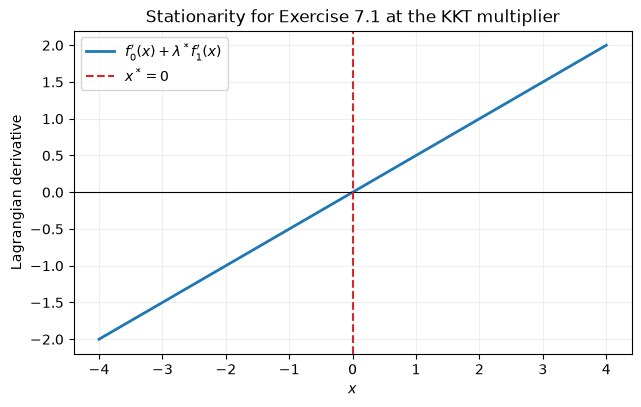

In [ ]:
# Both objectives are convex, and the displayed points satisfy all four KKT conditions.
def check_kkt_1d(x, lam, f1, df0, df1, name):
    primal = float(f1(x))
    stationarity = float(df0(x) + lam * df1(x))
    complementarity = float(lam * primal)
    assert primal <= 1e-10
    assert lam >= -1e-12
    assert np.isclose(stationarity, 0.0, atol=1e-10)
    assert np.isclose(complementarity, 0.0, atol=1e-10)
    print(f"{name}: x*={x:.8f}, lambda*={lam:.8f}; "
          f"primal={primal:.2e}, lambda={lam:.2e}, "
          f"stationarity={stationarity:.2e}, complementarity={complementarity:.2e}")

# min -x subject to exp(x)-1 <= 0; the feasible half-line is x <= 0.
f_exp = lambda z: -z[0]
g_exp = lambda z: np.expm1(z[0])
res_exp = minimize(f_exp, np.array([-1.0]), jac=lambda z: np.array([-1.0]),
                   constraints=[{"type": "ineq", "fun": lambda z: -g_exp(z),
                                 "jac": lambda z: np.array([-np.exp(z[0])])}],
                   method="SLSQP", options={"ftol": 1e-13, "maxiter": 500})
assert res_exp.success, res_exp.message
x_exp, lam_exp = 0.0, 1.0
assert np.allclose(res_exp.x, [x_exp], atol=1e-8)
check_kkt_1d(x_exp, lam_exp, lambda x: np.expm1(x), lambda x: -1.0,
             lambda x: np.exp(x), "min -x, exp(x)-1 <= 0")
# At lambda=1, inf_x L(x,lambda)=0, matching the primal value.
dual_exp = np.log(lam_exp) + 1.0 - lam_exp
assert np.isclose(-x_exp - dual_exp, 0.0, atol=1e-12)

# Exercise 7.1: min x^2/4 - x subject to x <= 0.
f_q = lambda x: 0.25 * x**2 - x
df_q = lambda x: 0.5 * x - 1.0
res_q = minimize(lambda z: f_q(z[0]), np.array([-1.0]),
                 jac=lambda z: np.array([df_q(z[0])]),
                 constraints=[{"type": "ineq", "fun": lambda z: -z[0],
                               "jac": lambda z: np.array([-1.0])}],
                 method="SLSQP", options={"ftol": 1e-13, "maxiter": 500})
assert res_q.success, res_q.message
x_q, lam_q = 0.0, 1.0
assert np.allclose(res_q.x, [x_q], atol=1e-8)
check_kkt_1d(x_q, lam_q, lambda x: x, df_q, lambda x: 1.0,
             "Exercise 7.1, x <= 0")
# The Lagrangian is x^2/4 at lambda=1, so its infimum equals p*.
dual_q = f_q(x_q) + lam_q * x_q
assert np.isclose(f_q(x_q) - dual_q, 0.0, atol=1e-12)

# Change the constraint to x <= 3. The unconstrained minimizer x=2 is feasible.
res_q3 = minimize(lambda z: f_q(z[0]), np.array([0.0]),
                  jac=lambda z: np.array([df_q(z[0])]),
                  constraints=[{"type": "ineq", "fun": lambda z: 3.0 - z[0],
                                "jac": lambda z: np.array([-1.0])}],
                  method="SLSQP", options={"ftol": 1e-13, "maxiter": 500})
assert res_q3.success, res_q3.message
x_q3, lam_q3 = 2.0, 0.0
assert np.allclose(res_q3.x, [x_q3], atol=1e-8)
check_kkt_1d(x_q3, lam_q3, lambda x: x - 3.0, df_q,
             lambda x: 1.0, "Exercise 7.1, x <= 3")
assert np.isclose(f_q(x_q3), -1.0)
assert np.isclose(f_q(x_q3) - (f_q(x_q3) + lam_q3 * (x_q3 - 3.0)), 0.0)

x_grid = np.linspace(-4.0, 4.0, 500)
lagrangian_gradient = df_q(x_grid) + lam_q
assert np.isclose(lagrangian_gradient[np.argmin(np.abs(x_grid - x_q))], 0.0,
                  atol=5e-3)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(x_grid, lagrangian_gradient, lw=2,
        label=r"$f_0'(x)+\lambda^* f_1'(x)$")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(x_q, color="tab:red", ls="--", label=r"$x^*=0$")
ax.set(xlabel="$x$", ylabel="Lagrangian derivative",
       title="Stationarity for Exercise 7.1 at the KKT multiplier")
ax.legend()
ax.grid(alpha=0.2)
plt.show()


### Explain
For both original inequalities the optimum lies on the boundary, so the constraint is active and its multiplier balances the objective gradient. Complementary slackness holds because the active constraint has zero residual. With the relaxed upper bound, the unconstrained minimizer is feasible; the constraint is inactive, its multiplier is zero, and stationarity reduces to the unconstrained first-order condition.

## 9.2 KKT geometry in 2-D [CO 14.5]

### Task
Solve $\min_x (x_1-2)^2+(x_2-2)^2$ subject to $x_1+x_2\le2$, $x_1\ge0$, and $x_2\ge0$ with SLSQP. Draw $-\nabla f_0(x^*)$ and the active constraint gradients, then recover the multipliers from stationarity.

### Explore
Move the target with sliders. Inspect the active set and multipliers, including the targets $(3,-1)$, $(0.5,0.5)$, and $(-1,-1)$.

### Explain
Why is the negative objective gradient in the cone of active constraint gradients? What do zero multipliers mean?

target=(2, 2)
x* = [1. 1.]  active = ['x1+x2=2']
lambda* = [2. 0. 0.]  stationarity residual = [-0. -0.]
-grad f0 = [2. 2.] sum lambda_i grad g_i = [2. 2.] duality gap = 0.0


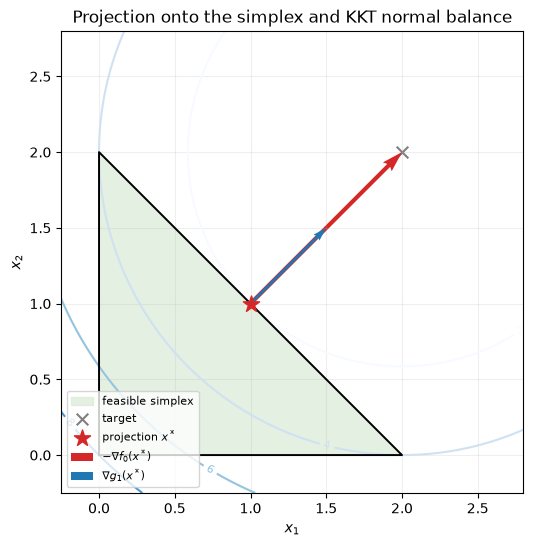

In [ ]:
# Write every inequality as A_i x - b_i <= 0.
A_proj = np.array([[1.0, 1.0], [-1.0, 0.0], [0.0, -1.0]])
b_proj = np.array([2.0, 0.0, 0.0])
constraint_names = ["x1+x2=2", "x1=0", "x2=0"]

def projection_objective(x, target):
    return float(np.sum((x - target) ** 2))

def projection_gradient(x, target):
    return 2.0 * (x - target)

def projection_constraints(x):
    return A_proj @ x - b_proj

def solve_projection(target):
    target = np.asarray(target, dtype=float)
    res = minimize(lambda x: projection_objective(x, target),
                   np.array([0.5, 0.5]),
                   jac=lambda x: projection_gradient(x, target),
                   constraints=[{"type": "ineq",
                                 "fun": lambda x: b_proj - A_proj @ x,
                                 "jac": lambda x: -A_proj}],
                   method="SLSQP", options={"ftol": 1e-12, "maxiter": 500})
    assert res.success, res.message
    x_star = res.x
    g_star = projection_constraints(x_star)
    active = np.flatnonzero(g_star >= -1e-7)
    lam = np.zeros(3)
    if len(active):
        lam[active], _ = nnls(A_proj[active].T,
                              -projection_gradient(x_star, target))
    stationarity = projection_gradient(x_star, target) + A_proj.T @ lam
    complementarity = lam * g_star
    assert np.max(g_star) <= 1e-8
    assert np.min(lam) >= 0.0
    assert np.allclose(stationarity, 0.0, atol=2e-7)
    assert np.allclose(complementarity, 0.0, atol=2e-7)
    # Stationarity makes x_star the minimizer of this strongly convex Lagrangian.
    dual_value = projection_objective(x_star, target) + lam @ g_star
    raw_gap = projection_objective(x_star, target) - dual_value
    assert raw_gap >= -2e-7
    gap = max(0.0, raw_gap)
    assert np.isclose(gap, 0.0, atol=2e-7)
    return {"res": res, "x": x_star, "lambda": lam, "g": g_star,
            "active": active, "gap": gap, "stationarity": stationarity}

base_projection = solve_projection((2.0, 2.0))
base_x = base_projection["x"]
base_lam = base_projection["lambda"]
base_active = base_projection["active"]
base_target = np.array([2.0, 2.0])
base_negative_gradient = -projection_gradient(base_x, base_target)
scaled_normals = A_proj[base_active].T @ base_lam[base_active]
assert np.allclose(base_negative_gradient, scaled_normals, atol=1e-8)
print("target=(2, 2)")
print("x* =", base_x, " active =", [constraint_names[i] for i in base_active])
print("lambda* =", base_lam, " stationarity residual =", base_projection["stationarity"])
print("-grad f0 =", base_negative_gradient, "sum lambda_i grad g_i =", scaled_normals,
      "duality gap =", base_projection["gap"])

# Numerical gradients of the objective and affine constraints agree with their formulas.
h_fd = 1e-6
fd_grad = np.array([(projection_objective(base_x + h_fd*np.eye(2)[j], base_target)
                     - projection_objective(base_x - h_fd*np.eye(2)[j], base_target))
                    / (2*h_fd) for j in range(2)])
assert np.allclose(fd_grad, projection_gradient(base_x, base_target), atol=1e-8)
assert np.allclose((projection_constraints(base_x + h_fd*np.eye(2)[0])
                    - projection_constraints(base_x - h_fd*np.eye(2)[0]))/(2*h_fd),
                   A_proj[:, 0], atol=1e-9)

# Contours, feasible triangle, optimum, and the KKT balance at the (2,2) target.
xx, yy = np.meshgrid(np.linspace(-0.25, 2.8, 260), np.linspace(-0.25, 2.8, 260))
zz = (xx - base_target[0])**2 + (yy - base_target[1])**2
fig, ax = plt.subplots(figsize=(6.8, 6.0))
cs = ax.contour(xx, yy, zz, levels=[2, 4, 6, 8, 12], cmap="Blues")
ax.clabel(cs, inline=True, fontsize=8, fmt="%.0f")
triangle = np.array([[0, 0], [2, 0], [0, 2], [0, 0]])
ax.fill(triangle[:, 0], triangle[:, 1], color="#dcebd8", alpha=0.75,
        label="feasible simplex")
ax.plot(triangle[:, 0], triangle[:, 1], color="black", lw=1.4)
ax.scatter(*base_target, marker="x", s=70, color="tab:gray", label="target")
ax.scatter(*base_x, marker="*", s=150, color="tab:red", label="projection $x^*$", zorder=5)
# Draw the negative objective gradient and each unscaled active constraint normal.
ax.quiver(*base_x, *base_negative_gradient, angles="xy", scale_units="xy", scale=2.0,
          color="tab:red", width=0.009, label=r"$-\nabla f_0(x^*)$")
for i in base_active:
    ax.quiver(*base_x, *A_proj[i], angles="xy", scale_units="xy", scale=2.0,
              color="tab:blue", width=0.006, label=rf"$\nabla g_{i+1}(x^*)$")
ax.set(xlim=(-0.25, 2.8), ylim=(-0.25, 2.8), xlabel="$x_1$", ylabel="$x_2$",
       title="Projection onto the simplex and KKT normal balance")
ax.set_aspect("equal")
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.2)
plt.show()


### Explore: target sweep and interactive sliders
The active set changes with the target. The static panels below preserve the requested examples in the saved notebook; the sliders let you inspect other targets interactively.

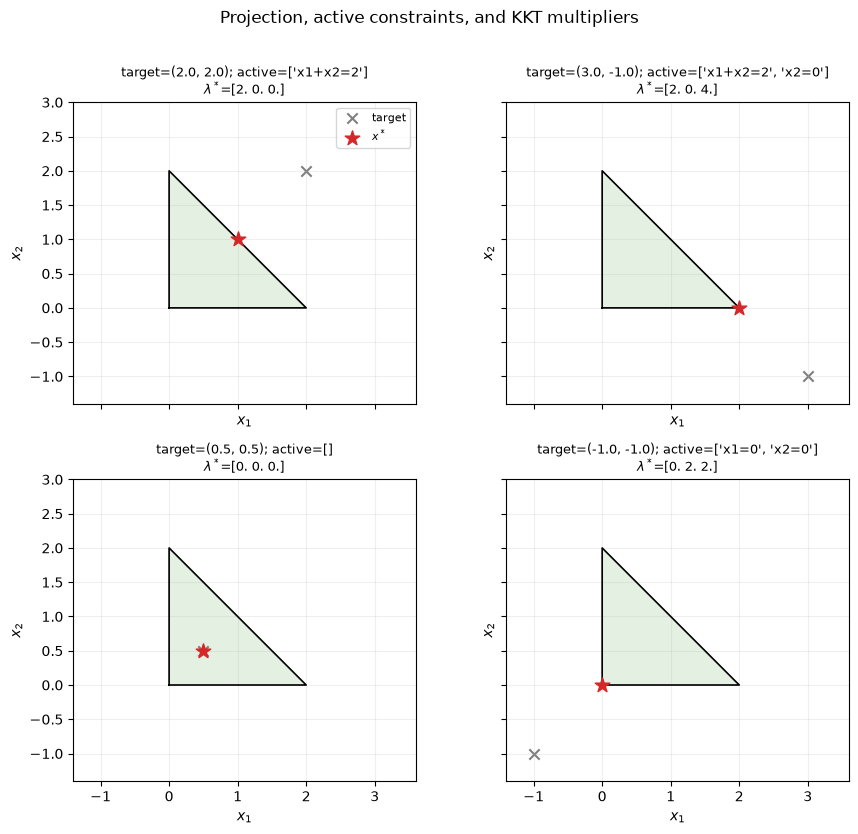

target=(2.0, 2.0): x*=[1. 1.], active=['x1+x2=2'], lambda*=[2. 0. 0.], stationarity_inf=2.22e-16, gap=0.00e+00
target=(3.0, -1.0): x*=[ 2. -0.], active=['x1+x2=2', 'x2=0'], lambda*=[2. 0. 4.], stationarity_inf=0.00e+00, gap=0.00e+00
target=(0.5, 0.5): x*=[0.5 0.5], active=[], lambda*=[0. 0. 0.], stationarity_inf=0.00e+00, gap=0.00e+00
target=(-1.0, -1.0): x*=[-0. -0.], active=['x1=0', 'x2=0'], lambda*=[0. 2. 2.], stationarity_inf=0.00e+00, gap=0.00e+00


In [ ]:
targets_2d = [(2.0, 2.0), (3.0, -1.0), (0.5, 0.5), (-1.0, -1.0)]
fig, axes = plt.subplots(2, 2, figsize=(9.2, 8.2), sharex=True, sharey=True)
triangle = np.array([[0, 0], [2, 0], [0, 2], [0, 0]])
for ax, target in zip(axes.flat, targets_2d):
    sol = solve_projection(target)
    ax.fill(triangle[:, 0], triangle[:, 1], color="#dcebd8", alpha=0.75)
    ax.plot(triangle[:, 0], triangle[:, 1], color="black", lw=1.2)
    ax.scatter(*target, marker="x", s=55, color="tab:gray", label="target")
    ax.scatter(*sol["x"], marker="*", s=120, color="tab:red", label="$x^*$", zorder=4)
    active_names = [constraint_names[i] for i in sol["active"]]
    ax.set_title(f"target={target}; active={active_names}\n$\\lambda^*$={sol['lambda']}", fontsize=9)
    ax.set(xlim=(-1.4, 3.6), ylim=(-1.4, 3.0), xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle("Projection, active constraints, and KKT multipliers", y=1.01)
fig.tight_layout()
plt.show()

for target in targets_2d:
    sol = solve_projection(target)
    active_names = [constraint_names[i] for i in sol["active"]]
    print(f"target={target}: x*={sol['x']}, active={active_names}, "
          f"lambda*={sol['lambda']}, stationarity_inf={np.linalg.norm(sol['stationarity'], np.inf):.2e}, "
          f"gap={sol['gap']:.2e}")


In [ ]:
target_x = widgets.FloatSlider(value=2.0, min=-1.5, max=3.5, step=0.1,
                              description="target x1", continuous_update=False)
target_y = widgets.FloatSlider(value=2.0, min=-1.5, max=3.0, step=0.1,
                              description="target x2", continuous_update=False)
projection_output = widgets.Output()

def redraw_projection(change=None):
    with projection_output:
        clear_output(wait=True)
        target = (target_x.value, target_y.value)
        sol = solve_projection(target)
        active_names = [constraint_names[i] for i in sol["active"]]
        print(f"target={target}; x*={sol['x']}")
        print(f"active={active_names}; lambda*={sol['lambda']}")
        print(f"stationarity_inf={np.linalg.norm(sol['stationarity'], np.inf):.2e}; "
              f"duality_gap={sol['gap']:.2e}")
        fig, ax = plt.subplots(figsize=(4.6, 4.0))
        tri = np.array([[0, 0], [2, 0], [0, 2], [0, 0]])
        ax.fill(tri[:, 0], tri[:, 1], color="#dcebd8", alpha=0.75)
        ax.plot(tri[:, 0], tri[:, 1], color="black")
        ax.scatter(*target, marker="x", s=65, color="tab:gray", label="target")
        ax.scatter(*sol["x"], marker="*", s=130, color="tab:red", label="$x^*$")
        ax.set(xlim=(-1.6, 3.7), ylim=(-1.6, 3.2), xlabel="$x_1$", ylabel="$x_2$",
               title="Euclidean projection")
        ax.set_aspect("equal")
        ax.legend()
        ax.grid(alpha=0.2)
        plt.show()
        plt.close(fig)

target_x.observe(redraw_projection, names="value")
target_y.observe(redraw_projection, names="value")
projection_panel = widgets.VBox([widgets.HBox([target_x, target_y]), projection_output])
display(projection_panel)
redraw_projection()


### Explain
At a constrained minimum, feasible first-order directions cannot decrease the objective, so its negative gradient must be a nonnegative combination of the active constraint normals. Inactive constraints have zero multipliers by complementary slackness. An active constraint may also have zero multiplier: it touches the solution but does not contribute to the normal balance, as can occur at a transition between active sets.

## 9.3 Gradient descent, steepest descent and Newton on a Gaussian [CO 15.3–15.5]

### Task
Minimize $f(x)=\tfrac12(x-\mu)^T\Sigma^{-1}(x-\mu)$, with $\mu=(1,2)^T$ and $\Sigma=\begin{bmatrix}9&4\\4&2.5\end{bmatrix}$. Check the Hessian condition number. From a distant start, implement gradient descent, steepest descent in the diagonal Hessian norm, and Newton's method using backtracking with $\alpha=0.3$, $\beta=0.8$. Plot their paths and objective gaps.

### Explore
Increase the covariance correlation, compare with diagonal covariances, and replace backtracking with fixed-step gradient descent to locate the stability limit.

### Explain
Why does gradient descent zig-zag? How does diagonal scaling help? Why does Newton take one step here, and what happens to the contours under $x=\mu+\Sigma^{1/2}z$?

Gradient descent           : iterations= 232, final objective=4.886e-20, gradient_inf=8.55e-11
Diagonal steepest descent  : iterations= 131, final objective=3.493e-20, gradient_inf=8.80e-11
Newton                     : iterations=   1, final objective=1.165e-29, gradient_inf=1.09e-15
Hessian eigenvalues=[0.09171 1.67752], condition number=18.2915


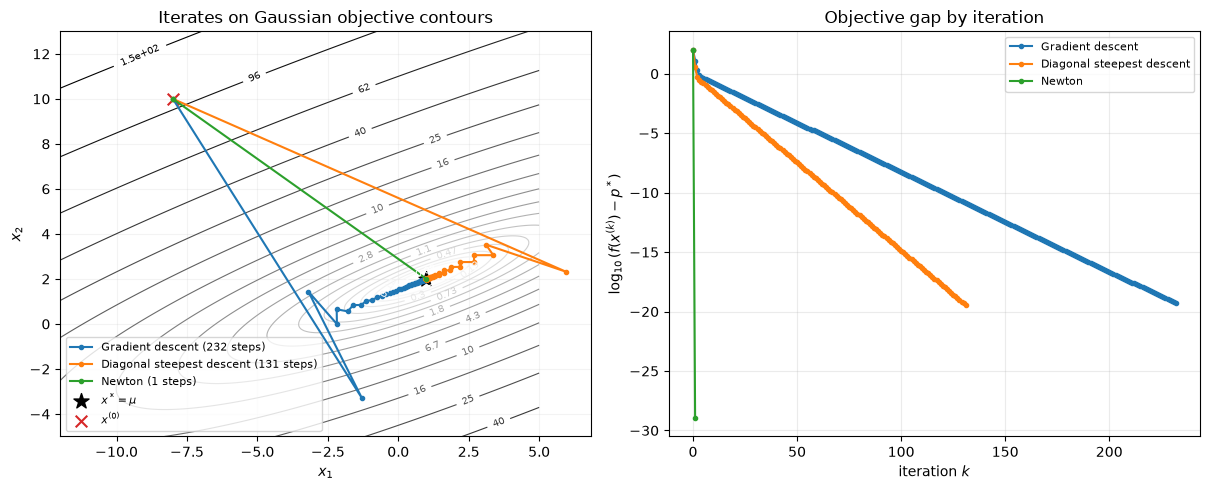

In [ ]:
mu_g = np.array([1.0, 2.0])
Sigma_g = np.array([[9.0, 4.0], [4.0, 2.5]])
H_g = np.linalg.inv(Sigma_g)
x0_g = np.array([-8.0, 10.0])

assert np.allclose(Sigma_g, Sigma_g.T)
assert np.all(np.linalg.eigvalsh(Sigma_g) > 0)
kappa_g = np.linalg.cond(H_g)
assert 15.0 < kappa_g < 20.0

def gaussian_objective(x, H=H_g, mu=mu_g):
    d = np.asarray(x) - mu
    return 0.5 * d @ H @ d

def gaussian_gradient(x, H=H_g, mu=mu_g):
    return H @ (np.asarray(x) - mu)

def backtracking_quadratic(H, P, x0=x0_g, mu=mu_g, alpha=0.3, beta=0.8,
                           maxiter=5000, tol=1e-10):
    x = np.asarray(x0, dtype=float).copy()
    xs, values = [x.copy()], [gaussian_objective(x, H, mu)]
    for _ in range(maxiter):
        grad = H @ (x - mu)
        if np.linalg.norm(grad) <= tol:
            break
        direction = -np.linalg.solve(P, grad)
        directional_derivative = grad @ direction
        assert directional_derivative < 0.0
        step = 1.0
        while gaussian_objective(x + step * direction, H, mu) > (
                gaussian_objective(x, H, mu) + alpha * step * directional_derivative):
            step *= beta
            assert step > 1e-16, "backtracking step underflow"
        x = x + step * direction
        xs.append(x.copy())
        values.append(gaussian_objective(x, H, mu))
    assert np.linalg.norm(H @ (x - mu)) <= 2e-9
    assert np.all(np.diff(values) <= 1e-12)
    return np.asarray(xs), np.asarray(values)

P_identity = np.eye(2)
P_diagonal = np.diag(np.diag(H_g))
paths_g = {
    "Gradient descent": backtracking_quadratic(H_g, P_identity),
    "Diagonal steepest descent": backtracking_quadratic(H_g, P_diagonal),
    "Newton": backtracking_quadratic(H_g, H_g),
}
res_gaussian = minimize(lambda x: gaussian_objective(x), x0_g,
                        jac=lambda x: gaussian_gradient(x),
                        hess=lambda x: H_g, method="trust-exact",
                        options={"gtol": 1e-12})
assert res_gaussian.success, res_gaussian.message
p_gaussian = gaussian_objective(res_gaussian.x)
assert np.allclose(res_gaussian.x, mu_g, atol=1e-9)
for name, (xs, values) in paths_g.items():
    assert np.allclose(xs[-1], res_gaussian.x, atol=2e-8)
    assert np.isclose(values[-1], p_gaussian, atol=1e-12)
    print(f"{name:27s}: iterations={len(xs)-1:4d}, "
          f"final objective={values[-1]:.3e}, gradient_inf="
          f"{np.linalg.norm(gaussian_gradient(xs[-1]), np.inf):.2e}")
print(f"Hessian eigenvalues={np.linalg.eigvalsh(H_g)}, condition number={kappa_g:.4f}")

# Check the analytic gradient against finite differences at a point away from the minimizer.
x_check_g = np.array([-2.3, 5.1])
h_fd = 1e-6
fd_grad_g = np.array([(gaussian_objective(x_check_g + h_fd*np.eye(2)[j])
                       - gaussian_objective(x_check_g - h_fd*np.eye(2)[j]))
                      / (2*h_fd) for j in range(2)])
assert np.allclose(fd_grad_g, gaussian_gradient(x_check_g), atol=2e-8)
assert np.allclose(H_g, H_g.T)

# Verify the affine change x=mu+Sigma^(1/2) z turns the contours into circles.
Sigma_half = np.linalg.cholesky(Sigma_g)
z_check = np.array([0.7, -1.2])
x_from_z = mu_g + Sigma_half @ z_check
assert np.isclose(gaussian_objective(x_from_z), 0.5 * (z_check @ z_check), atol=1e-12)

fig, (ax_path, ax_gap) = plt.subplots(1, 2, figsize=(12.2, 5.0))
grid_x = np.linspace(-12, 5, 250)
grid_y = np.linspace(-5, 13, 250)
GX, GY = np.meshgrid(grid_x, grid_y)
GZ = 0.5 * (H_g[0, 0]*(GX-mu_g[0])**2
            + 2*H_g[0, 1]*(GX-mu_g[0])*(GY-mu_g[1])
            + H_g[1, 1]*(GY-mu_g[1])**2)
contours = ax_path.contour(GX, GY, GZ, levels=np.geomspace(0.08, 150, 18),
                           norm="log", cmap="Greys", linewidths=0.8)
ax_path.clabel(contours, inline=True, fontsize=7, fmt="%.2g")
colors = ["tab:blue", "tab:orange", "tab:green"]
for (name, (xs, values)), color in zip(paths_g.items(), colors):
    ax_path.plot(xs[:, 0], xs[:, 1], "o-", ms=3, lw=1.5, color=color,
                 label=f"{name} ({len(xs)-1} steps)")
ax_path.scatter(*mu_g, marker="*", color="black", s=130, label=r"$x^*=\mu$")
ax_path.scatter(*x0_g, marker="x", color="tab:red", s=70, label="$x^{(0)}$")
ax_path.set(xlabel="$x_1$", ylabel="$x_2$", title="Iterates on Gaussian objective contours")
ax_path.legend(fontsize=8)
ax_path.grid(alpha=0.15)
for (name, (xs, values)), color in zip(paths_g.items(), colors):
    gaps = np.maximum(values - p_gaussian, 1e-30)
    ax_gap.plot(np.arange(len(gaps)), np.log10(gaps), "o-", ms=3, color=color, label=name)
ax_gap.set(xlabel="iteration $k$", ylabel=r"$\log_{10}(f(x^{(k)})-p^*)$",
           title="Objective gap by iteration")
ax_gap.legend(fontsize=8)
ax_gap.grid(alpha=0.25)
fig.tight_layout()
plt.show()


### Explore: covariance, preconditioning and fixed steps

off-diagonal=4.0: kappa(Sigma^-1)=18.2915
off-diagonal=4.5: kappa(Sigma^-1)=56.7602
off-diagonal=4.7: kappa(Sigma^-1)=320.5579
correlated [9,4;4,2.5]   : kappa= 18.291, GD steps= 232, diagonal-norm steps= 131
diagonal [9,2.5]         : kappa=  3.600, GD steps= 196, diagonal-norm steps=   1
diagonal [9,0.5]         : kappa= 18.000, GD steps= 210, diagonal-norm steps=   1
GD converges for 0 < t < 2/lambda_max(H); stability boundary (supremum)=1.192236
At 0.99 of the boundary: f_final=9.041e-20; at 1.01: f_final=4.508e+22


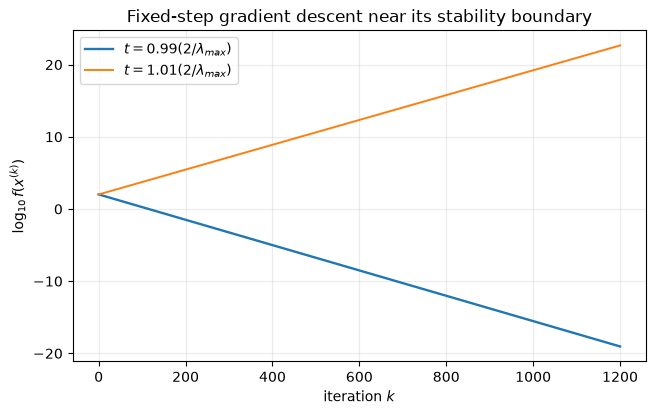

In [ ]:
# Correlation changes conditioning while preserving the marginal variances.
for covariance in [4.0, 4.5, 4.7]:
    Sigma_variant = np.array([[9.0, covariance], [covariance, 2.5]])
    assert np.all(np.linalg.eigvalsh(Sigma_variant) > 0)
    print(f"off-diagonal={covariance:.1f}: kappa(Sigma^-1)="
          f"{np.linalg.cond(np.linalg.inv(Sigma_variant)):.4f}")

# A diagonal metric removes axis-wise scaling for diagonal covariances, but
# cannot remove the rotated eigendirections of a correlated covariance.
covariance_cases = {
    "correlated [9,4;4,2.5]": Sigma_g,
    "diagonal [9,2.5]": np.diag([9.0, 2.5]),
    "diagonal [9,0.5]": np.diag([9.0, 0.5]),
}
for label, Sigma_case in covariance_cases.items():
    H_case = np.linalg.inv(Sigma_case)
    plain = backtracking_quadratic(H_case, np.eye(2))
    diagonal = backtracking_quadratic(H_case, np.diag(np.diag(H_case)))
    assert np.allclose(plain[0][-1], mu_g, atol=2e-8)
    assert np.allclose(diagonal[0][-1], mu_g, atol=2e-8)
    print(f"{label:25s}: kappa={np.linalg.cond(H_case):7.3f}, "
          f"GD steps={len(plain[0])-1:4d}, diagonal-norm steps={len(diagonal[0])-1:4d}")

# For fixed-step GD on this quadratic, convergence requires 0 < t < 2/lambda_max(H).
lambda_max_g = np.linalg.eigvalsh(H_g)[-1]
t_limit = 2.0 / lambda_max_g
assert np.isclose(t_limit, 2.0 / lambda_max_g)

def fixed_step_path(H, t, x0=x0_g, mu=mu_g, iterations=1200):
    x = np.asarray(x0, dtype=float).copy()
    values = [gaussian_objective(x, H, mu)]
    for _ in range(iterations):
        x = x - t * (H @ (x - mu))
        values.append(gaussian_objective(x, H, mu))
    return np.asarray(values), x

stable_values, stable_x = fixed_step_path(H_g, 0.99 * t_limit)
unstable_values, unstable_x = fixed_step_path(H_g, 1.01 * t_limit)
assert np.linalg.norm(stable_x - mu_g) < 1e-7
assert unstable_values[-1] > unstable_values[0]
print(f"GD converges for 0 < t < 2/lambda_max(H); stability boundary (supremum)="
      f"{t_limit:.6f}")
print(f"At 0.99 of the boundary: f_final={stable_values[-1]:.3e}; "
      f"at 1.01: f_final={unstable_values[-1]:.3e}")

fig, ax = plt.subplots(figsize=(7.4, 4.3))
ax.plot(np.log10(np.maximum(stable_values, 1e-30)), lw=1.7,
        label=rf"$t=0.99(2/\lambda_{{max}})$")
ax.plot(np.log10(np.maximum(unstable_values, 1e-30)), lw=1.4,
        label=rf"$t=1.01(2/\lambda_{{max}})$")
ax.set(xlabel="iteration $k$", ylabel=r"$\log_{10} f(x^{(k)})$",
       title="Fixed-step gradient descent near its stability boundary")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


### Explain
The elongated, rotated level sets make the Euclidean gradient repeatedly overshoot across the narrow direction while making slow progress along the long one; iteration counts therefore worsen with conditioning. Diagonal scaling compensates for unequal coordinate scales but cannot undo correlated, rotated curvature. For a quadratic, Newton applies the inverse Hessian exactly. In whitened coordinates its ellipses become circles, and the Newton step is ordinary unit-step gradient descent.

## 9.4 Nonlinear regression: gradient descent, Gauss–Newton and Adam [MLE 1.7.3–1.7.5]

### Task
Generate $m=50$ observations $y_i=\theta_1e^{-\theta_2t_i}+\epsilon_i$ on $[0,5]$, with $\theta=(3,0.8)$ and Gaussian noise of standard deviation $0.1$. Minimize $J(\theta)=\|r(\theta)\|_2^2$, derive the residual Jacobian, implement fixed-step gradient descent, Gauss–Newton and Adam, and compare with scipy.optimize.curve_fit. The residual Jacobian is $[J_r]_{i,:}=(-e^{-\theta_2t_i},\theta_1t_i e^{-\theta_2t_i})$.

### Explore
Try initial points $(1,0.1)$ and $(1,3)$, vary the learning rates, use random mini-batches for Adam, and add Levenberg–Marquardt damping when a Gauss–Newton step fails.

### Explain
Is $J$ convex? Why can Gauss–Newton work without a stepsize and behave like Newton near a small-residual solution? How does Adam's coordinate scaling relate to steepest descent, and which method suits this problem versus a very large neural network?

In [ ]:
# Synthetic data: every stochastic experiment has its own reproducible seed.
m_data = 50
t_data = np.linspace(0.0, 5.0, m_data)
theta_true = np.array([3.0, 0.8])
noise_data = np.random.default_rng(2026).normal(0.0, 0.1, size=m_data)
y_data = theta_true[0] * np.exp(-theta_true[1] * t_data) + noise_data

def regression_model(t, theta):
    return theta[0] * np.exp(-theta[1] * t)

def residual_vector(theta, indices=None):
    if indices is None:
        indices = np.arange(m_data)
    tt = t_data[indices]
    yy = y_data[indices]
    return yy - regression_model(tt, theta)

def residual_jacobian(theta, indices=None):
    if indices is None:
        indices = np.arange(m_data)
    tt = t_data[indices]
    e = np.exp(-theta[1] * tt)
    return np.column_stack((-e, theta[0] * tt * e))

def regression_objective(theta, indices=None):
    r = residual_vector(theta, indices)
    return float(r @ r)

def regression_gradient(theta, indices=None, scale=1.0):
    return 2.0 * scale * residual_jacobian(theta, indices).T @ residual_vector(theta, indices)

# Verify the hand-derived Jacobian and objective gradient by finite differences.
theta_check = np.array([2.4, 0.6])
h_fd = 1e-6
J_fd = np.column_stack([(residual_vector(theta_check + h_fd*np.eye(2)[j])
                         - residual_vector(theta_check - h_fd*np.eye(2)[j]))/(2*h_fd)
                        for j in range(2)])
assert np.allclose(J_fd, residual_jacobian(theta_check), rtol=2e-7, atol=2e-8)
grad_fd = np.array([(regression_objective(theta_check + h_fd*np.eye(2)[j])
                     - regression_objective(theta_check - h_fd*np.eye(2)[j]))/(2*h_fd)
                    for j in range(2)])
assert np.allclose(grad_fd, regression_gradient(theta_check), rtol=2e-7, atol=2e-7)

# Fixed-step gradient descent on the full-data objective.
def regression_gradient_descent(theta0, eta=0.005, maxiter=5000, tol=1e-8):
    theta = np.asarray(theta0, dtype=float).copy()
    path = [theta.copy()]
    for _ in range(maxiter):
        grad = regression_gradient(theta)
        if np.linalg.norm(grad) <= tol:
            break
        theta_next = theta - eta * grad
        if not np.all(np.isfinite(theta_next)) or regression_objective(theta_next) > 1e12:
            return {"path": np.asarray(path), "success": False, "reason": "diverged"}
        theta = theta_next
        path.append(theta.copy())
    return {"path": np.asarray(path), "success": np.linalg.norm(regression_gradient(theta)) <= tol,
            "reason": "gradient tolerance"}

# Full-step Gauss–Newton: theta <- theta - J_r^+ r; report rejected full steps.
def regression_gauss_newton(theta0, maxiter=100, tol=1e-8):
    theta = np.asarray(theta0, dtype=float).copy()
    path = [theta.copy()]
    rejected = None
    for _ in range(maxiter):
        r = residual_vector(theta)
        Jr = residual_jacobian(theta)
        grad = 2.0 * Jr.T @ r
        if np.linalg.norm(grad) <= tol:
            return {"path": np.asarray(path), "success": True, "rejected": rejected}
        step = -np.linalg.pinv(Jr) @ r
        assert np.allclose(Jr.T @ Jr @ step, -Jr.T @ r, atol=2e-8)
        candidate = theta + step
        if (not np.all(np.isfinite(candidate))
                or regression_objective(candidate) >= regression_objective(theta)):
            rejected = candidate
            return {"path": np.asarray(path), "success": False, "rejected": rejected}
        theta = candidate
        path.append(theta.copy())
    return {"path": np.asarray(path), "success": False, "rejected": rejected}

# Adam with bias corrections; batch_size=None gives full-batch Adam.
def regression_adam(theta0, eta=0.05, batch_size=None, maxiter=5000,
                    tol=1e-6, random_state=None):
    theta = np.asarray(theta0, dtype=float).copy()
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8
    first = np.zeros(2)
    second = np.zeros(2)
    path = [theta.copy()]
    for k in range(1, maxiter + 1):
        if batch_size is None:
            indices = np.arange(m_data)
            scale = 1.0
        else:
            indices = random_state.choice(m_data, size=batch_size, replace=False)
            scale = m_data / batch_size
        grad = regression_gradient(theta, indices, scale)
        first = beta1 * first + (1.0 - beta1) * grad
        second = beta2 * second + (1.0 - beta2) * grad**2
        first_hat = first / (1.0 - beta1**k)
        second_hat = second / (1.0 - beta2**k)
        theta = theta - eta * first_hat / (np.sqrt(second_hat) + epsilon)
        path.append(theta.copy())
        if not np.all(np.isfinite(theta)) or regression_objective(theta) > 1e12:
            return {"path": np.asarray(path), "success": False}
        if batch_size is None and np.linalg.norm(regression_gradient(theta)) <= tol:
            break
    return {"path": np.asarray(path),
            "success": (batch_size is None and
                        np.linalg.norm(regression_gradient(theta)) <= tol)}

# Compare the three methods from the main initialization to scipy.optimize.curve_fit.
theta0_reg = np.array([1.0, 0.1])
fit_curve, covariance_curve = curve_fit(
    lambda t, theta1, theta2: theta1 * np.exp(-theta2 * t),
    t_data, y_data, p0=theta0_reg, maxfev=20000)
p_star_reg = regression_objective(fit_curve)
gd_reg = regression_gradient_descent(theta0_reg, eta=0.005)
gn_reg = regression_gauss_newton(theta0_reg)
adam_reg = regression_adam(theta0_reg, eta=0.05)
assert gd_reg["success"] and gn_reg["success"] and adam_reg["success"]
method_runs = [("Gradient descent", gd_reg), ("Gauss-Newton", gn_reg), ("Adam", adam_reg)]
for name, result in method_runs:
    theta_hat = result["path"][-1]
    value = regression_objective(theta_hat)
    assert value - p_star_reg >= -2e-7
    assert np.isclose(value, p_star_reg, atol=2e-7)
    assert np.allclose(theta_hat, fit_curve, atol=2e-5)
    print(f"{name:18s}: iterations={len(result['path'])-1:4d}, "
          f"theta={theta_hat}, J={value:.8f}, "
          f"||grad||={np.linalg.norm(regression_gradient(theta_hat)):.2e}")
print(f"curve_fit: theta={fit_curve}, J={p_star_reg:.8f}; "
      f"nonnegative objective gap={max(0.0, regression_objective(fit_curve)-p_star_reg):.2e}")


Gradient descent  : iterations= 608, theta=[2.94935 0.77473], J=0.51395859, ||grad||=9.80e-09
Gauss-Newton      : iterations=   7, theta=[2.94935 0.77473], J=0.51395859, ||grad||=5.24e-09
Adam              : iterations= 300, theta=[2.94935 0.77473], J=0.51395859, ||grad||=4.23e-07
curve_fit: theta=[2.94935 0.77473], J=0.51395859; nonnegative objective gap=0.00e+00


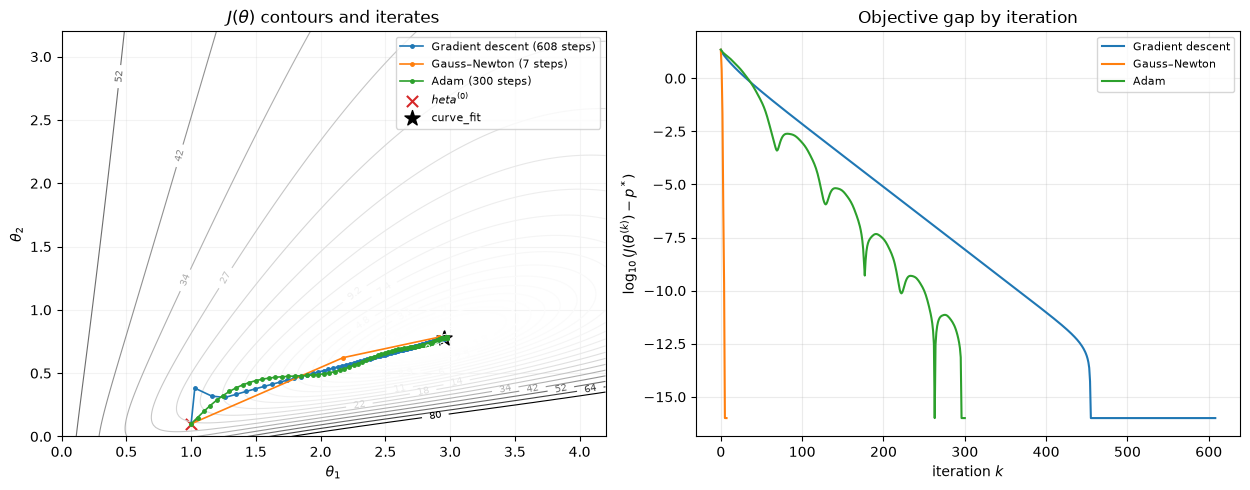

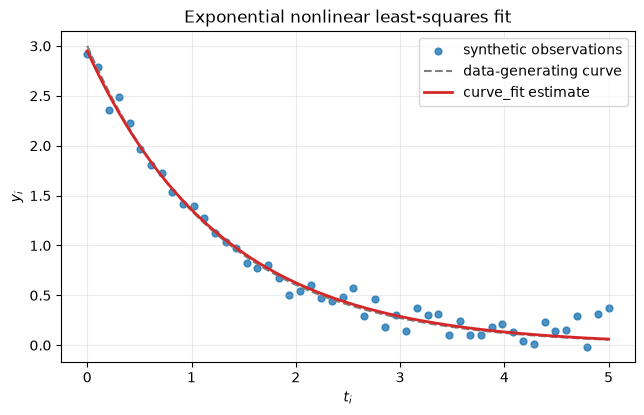

In [ ]:
# Contours, optimization paths, log objective gaps, and fitted curves.
theta1_grid = np.linspace(0.0, 4.2, 180)
theta2_grid = np.linspace(0.0, 3.2, 180)
T1, T2 = np.meshgrid(theta1_grid, theta2_grid)
model_grid = T1[..., None] * np.exp(-T2[..., None] * t_data)
J_grid = np.sum((y_data - model_grid)**2, axis=-1)

fig, (ax_contour, ax_loss) = plt.subplots(1, 2, figsize=(12.6, 5.0))
levels = np.geomspace(max(p_star_reg * 1.015, 0.55), max(80.0, J_grid.min()*1.1), 24)
contours = ax_contour.contour(T1, T2, J_grid, levels=levels, cmap="Greys", linewidths=0.8)
ax_contour.clabel(contours, inline=True, fontsize=7, fmt="%.2g")
path_items = [("Gradient descent", gd_reg["path"], "tab:blue"),
              ("Gauss–Newton", gn_reg["path"], "tab:orange"),
              ("Adam", adam_reg["path"], "tab:green")]
for name, path_reg, color in path_items:
    ax_contour.plot(path_reg[:, 0], path_reg[:, 1], "o-", ms=2.5, lw=1.2,
                    color=color, label=f"{name} ({len(path_reg)-1} steps)")
ax_contour.scatter(*theta0_reg, marker="x", color="tab:red", s=65, label="$\theta^{(0)}$")
ax_contour.scatter(*fit_curve, marker="*", color="black", s=130, label="curve_fit")
ax_contour.set(xlabel=r"$\theta_1$", ylabel=r"$\theta_2$",
               title=r"$J(\theta)$ contours and iterates")
ax_contour.legend(fontsize=8)
ax_contour.grid(alpha=0.15)
for name, path_reg, color in path_items:
    vals = np.array([regression_objective(theta) for theta in path_reg])
    gap = np.maximum(vals - p_star_reg, 1e-16)
    ax_loss.plot(np.arange(len(gap)), np.log10(gap), lw=1.5, color=color, label=name)
ax_loss.set(xlabel="iteration $k$", ylabel=r"$\log_{10}(J(\theta^{(k)})-p^*)$",
            title="Objective gap by iteration")
ax_loss.legend(fontsize=8)
ax_loss.grid(alpha=0.25)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.4, 4.3))
ax.scatter(t_data, y_data, s=24, alpha=0.8, label="synthetic observations")
t_dense = np.linspace(0.0, 5.0, 300)
ax.plot(t_dense, regression_model(t_dense, theta_true), "--", color="tab:gray",
        label="data-generating curve")
ax.plot(t_dense, regression_model(t_dense, fit_curve), color="tab:red", lw=2,
        label="curve_fit estimate")
ax.set(xlabel="$t_i$", ylabel="$y_i$", title="Exponential nonlinear least-squares fit")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


### Explore: alternate starts, learning rates, mini-batches and damping

alternate start=[1. 3.]; raw GN full-step success=False, rejected proposal=[  2.38576 -12.25563]
GD             : iterations= 599, theta=[2.94935 0.77473], J=0.51395859
LM-damped GN   : iterations=  10, theta=[2.94935 0.77473], J=0.51395859
Adam           : iterations= 340, theta=[2.94935 0.77473], J=0.51395859
GD eta=0.001: updates=2393, J=0.51395859, ||grad||=1.00e-06
GD eta=0.005: updates= 472, J=0.51395859, ||grad||=9.91e-07
GD eta=0.02: updates= 187, J=0.51395859, ||grad||=9.76e-07
Adam eta=0.01: updates=1004, J=0.51395859, ||grad||=9.84e-06
Adam eta=0.05: updates= 262, J=0.51395859, ||grad||=9.82e-06
Adam eta=0.2: updates= 247, J=0.51395859, ||grad||=7.09e-06
mini-batch Adam (batch=10, 2500 updates): theta=[2.93262 0.77135], J=0.51502701, full-data ||grad||=1.800e-01


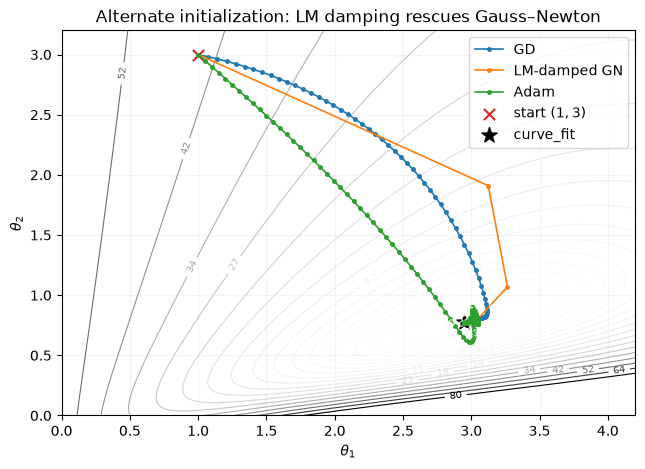

In [ ]:
# At (1,3), a raw full Gauss–Newton step increases J. LM damping accepts
# only a decreasing step using (J_r^T J_r + lambda I).
def regression_lm(theta0, maxiter=300, tol=1e-8, initial_damping=1e-3):
    theta = np.asarray(theta0, dtype=float).copy()
    damping = initial_damping
    path = [theta.copy()]
    for _ in range(maxiter):
        r = residual_vector(theta)
        Jr = residual_jacobian(theta)
        if np.linalg.norm(2.0 * Jr.T @ r) <= tol:
            return {"path": np.asarray(path), "success": True}
        normal = Jr.T @ Jr
        rhs = -Jr.T @ r
        accepted = False
        for _trial in range(16):
            step = np.linalg.solve(normal + damping * np.eye(2), rhs)
            candidate = theta + step
            if (np.all(np.isfinite(candidate))
                    and regression_objective(candidate) < regression_objective(theta)):
                theta = candidate
                path.append(theta.copy())
                damping = max(damping / 3.0, 1e-12)
                accepted = True
                break
            damping *= 10.0
        if not accepted:
            return {"path": np.asarray(path), "success": False}
    return {"path": np.asarray(path),
            "success": np.linalg.norm(regression_gradient(theta)) <= tol}

alternate_start = np.array([1.0, 3.0])
gd_alt = regression_gradient_descent(alternate_start, eta=0.005)
gn_alt = regression_gauss_newton(alternate_start)
lm_alt = regression_lm(alternate_start)
adam_alt = regression_adam(alternate_start, eta=0.05)
assert gd_alt["success"] and not gn_alt["success"]
assert lm_alt["success"] and adam_alt["success"]
assert np.allclose(lm_alt["path"][-1], fit_curve, atol=2e-5)
assert np.allclose(adam_alt["path"][-1], fit_curve, atol=2e-5)
print(f"alternate start={alternate_start}; raw GN full-step success={gn_alt['success']}, "
      f"rejected proposal={gn_alt['rejected']}")
for name, result in [("GD", gd_alt), ("LM-damped GN", lm_alt), ("Adam", adam_alt)]:
    print(f"{name:15s}: iterations={len(result['path'])-1:4d}, "
          f"theta={result['path'][-1]}, J={regression_objective(result['path'][-1]):.8f}")

# Learning-rate sweeps: use common initial values and report objective/gradient norms.
for eta in [0.001, 0.005, 0.02]:
    trial = regression_gradient_descent(theta0_reg, eta=eta, maxiter=2500, tol=1e-6)
    theta_hat = trial["path"][-1]
    print(f"GD eta={eta:.3g}: updates={len(trial['path'])-1:4d}, "
          f"J={regression_objective(theta_hat):.8f}, "
          f"||grad||={np.linalg.norm(regression_gradient(theta_hat)):.2e}")
for eta in [0.01, 0.05, 0.2]:
    trial = regression_adam(theta0_reg, eta=eta, maxiter=1500, tol=1e-5)
    theta_hat = trial["path"][-1]
    print(f"Adam eta={eta:.3g}: updates={len(trial['path'])-1:4d}, "
          f"J={regression_objective(theta_hat):.8f}, "
          f"||grad||={np.linalg.norm(regression_gradient(theta_hat)):.2e}")

# Stochastic Adam uses a separately seeded generator and unbiased mini-batch gradients.
rng_minibatch = np.random.default_rng(2026)
mini_adam = regression_adam(theta0_reg, eta=0.03, batch_size=10,
                            maxiter=2500, tol=0.0, random_state=rng_minibatch)
mini_theta = mini_adam["path"][-1]
print(f"mini-batch Adam (batch=10, 2500 updates): theta={mini_theta}, "
      f"J={regression_objective(mini_theta):.8f}, "
      f"full-data ||grad||={np.linalg.norm(regression_gradient(mini_theta)):.3e}")

fig, ax = plt.subplots(figsize=(7.4, 5.0))
contours = ax.contour(T1, T2, J_grid, levels=levels, cmap="Greys", linewidths=0.8)
ax.clabel(contours, inline=True, fontsize=7, fmt="%.2g")
for name, result, color in [("GD", gd_alt, "tab:blue"),
                            ("LM-damped GN", lm_alt, "tab:orange"),
                            ("Adam", adam_alt, "tab:green")]:
    path_reg = result["path"]
    ax.plot(path_reg[:, 0], path_reg[:, 1], "o-", ms=2.5, lw=1.2,
            color=color, label=name)
ax.scatter(*alternate_start, marker="x", s=65, color="tab:red", label="start $(1,3)$")
ax.scatter(*fit_curve, marker="*", s=130, color="black", label="curve_fit")
ax.set(xlabel=r"$\theta_1$", ylabel=r"$\theta_2$",
       title="Alternate initialization: LM damping rescues Gauss–Newton")
ax.legend()
ax.grid(alpha=0.15)
plt.show()


### Explain
The exponential dependence on the decay parameter makes the least-squares objective nonconvex, with curved valleys. Gauss–Newton minimizes the residual's local linear model, but a full step can increase the true objective; damping or a line search improves robustness. Near a good fit, the residual-weighted second-derivative term is small, so Gauss–Newton approximates Newton. Adam's adaptive diagonal scaling resembles a changing diagonal preconditioner; Gauss–Newton or Levenberg–Marquardt suits this small least-squares problem, while Adam scales better to noisy, massive models.